<div style="background-color:#003366; color:white; padding:16px; font-size:24px; font-weight:bold; border-radius:10px; text-align:center;">
  Quantum State-Based Encoding Schemes
</div>

<p style="font-size:20px; margin-top:12px; margin-left:10px;">Quantum state encoding allows quantum systems to represent data efficiently in forms suitable for quantum computation and communication.</p>



<!-- 1 -->
<div style="background-color:#ffcccc; color:#990000; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">1. Basis Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Simple one-to-one mapping of classical bits to quantum states.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Easy to implement and intuitive.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Not suitable for large-scale data or continuous values.</p>


In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile, assemble
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt

Statevector:
Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))


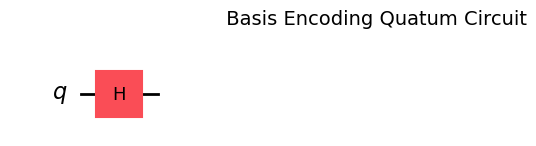

In [7]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile, assemble
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt

# Create a simple single-qubit circuit
qc = QuantumCircuit(1)
qc.h(0)  # example operation

backend = Aer.get_backend('statevector_simulator')
# Transpile the circuit
tqc = transpile(qc, backend)
# Run the circuit without assembling a Qobj explicitly
result = backend.run(tqc).result()
state = result.get_statevector()

print("Statevector:")
print(state)

# Plot the Dynamic Decoupling Circuit
fig = plt.figure(figsize=(2, 2))
ax = fig.add_subplot()
ax.text(1, 1, ' Basis Encoding Quatum Circuit', size=14)
qc.draw(output='mpl', ax=ax)
plt.show()

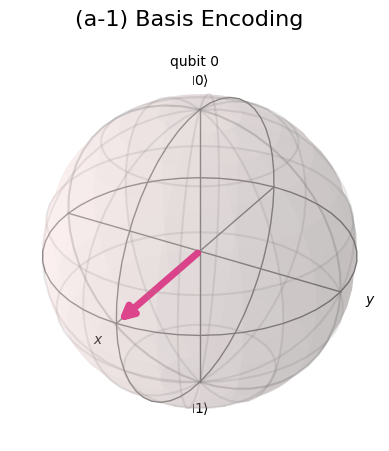

In [22]:
plot_bloch_multivector(state, title='(a-1) Basis Encoding')

Basis Encoding statevector:
Statevector([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j,
             0.+0.j],
            dims=(2, 2, 2))


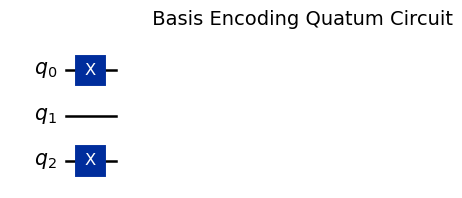

In [7]:
# Basis Encoding: Represent 5 as binary '101'
qc_basis = QuantumCircuit(3)
# Qiskit qubit ordering: [q2, q1, q0]. Set q0 and q2 to |1⟩.
qc_basis.x(0)  # LSB: bit 1
qc_basis.x(2)  # MSB: bit 1

backend = Aer.get_backend('statevector_simulator')
tqc = transpile(qc_basis, backend)
result = backend.run(tqc).result()
state = result.get_statevector()

print("Basis Encoding statevector:")
print(state)

# Plot the Dynamic Decoupling Circuit
fig = plt.figure(figsize=(2, 2))
ax = fig.add_subplot()
ax.text(1, 1, ' Basis Encoding Quatum Circuit', size=14)
qc_basis.draw(output='mpl', ax=ax)
plt.show()


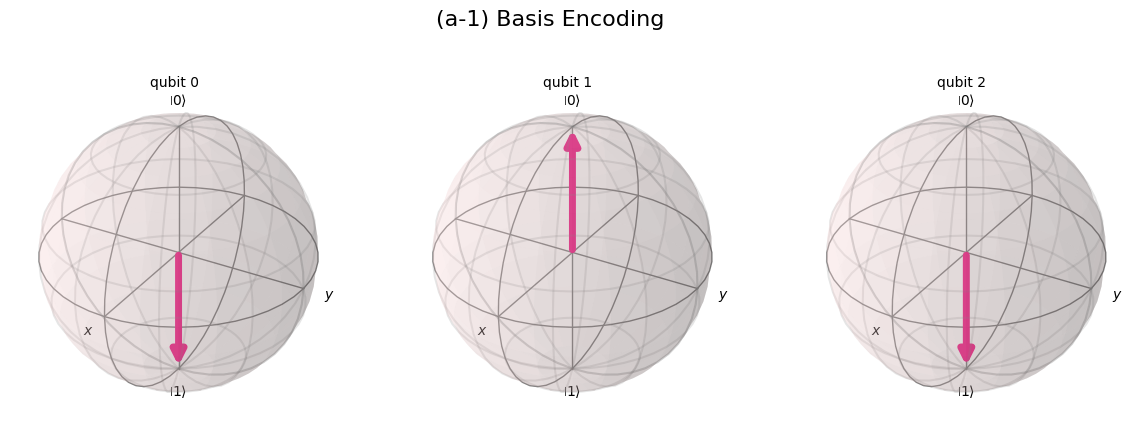

In [8]:
plot_bloch_multivector(state, title='(a-1) Basis Encoding')



<!-- 2 -->
<div style="background-color:#ccffcc; color:#006600; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">2. Amplitude Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Encodes data into amplitudes of quantum states.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Compresses high-dimensional data into fewer qubits.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Complex to prepare and requires normalization.</p>




In [9]:
import numpy as np

a = 1 / np.sqrt(1 + 5**2)
b = 5 / np.sqrt(1 + 5**2)
statevector = [a, b]

qc_amp = QuantumCircuit(1)
qc_amp.initialize(statevector, 0)

backend = Aer.get_backend('statevector_simulator')
tqc = transpile(qc_amp, backend)
result = backend.run(tqc).result()
state = result.get_statevector()

print("Amplitude Encoding statevector:")
print(state)

Amplitude Encoding statevector:
Statevector([0.19611614+0.j, 0.98058068+0.j],
            dims=(2,))


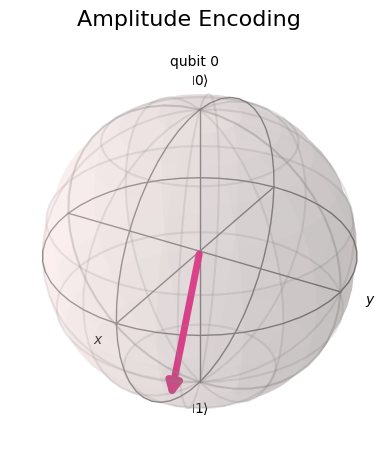

In [10]:
plot_bloch_multivector(state, title='Amplitude Encoding')


<!-- 3 -->
<div style="background-color:#ccccff; color:#000066; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">3. Angle Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Uses rotation gates to encode scalar values as angles.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Hardware-friendly and efficient.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Requires many qubits for large input sizes.</p>




In [11]:
qc_angle = QuantumCircuit(1)
theta = 5  # Use 5 directly; adjust scaling as needed
qc_angle.ry(theta, 0)

backend = Aer.get_backend('statevector_simulator')
tqc = transpile(qc_angle, backend)
result = backend.run(tqc).result()
state = result.get_statevector()

print("Angle Encoding statevector:")
print(state)


Angle Encoding statevector:
Statevector([-0.80114362+0.j,  0.59847214+0.j],
            dims=(2,))


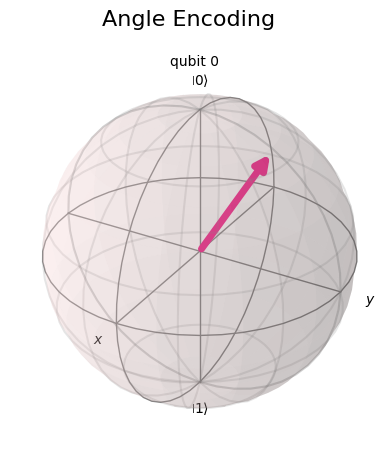

In [12]:
plot_bloch_multivector(state, title='Angle Encoding')


<!-- 4 -->
<div style="background-color:#ffffcc; color:#666600; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">4. Phase Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Embeds values in the phase of quantum states.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Works well with interference-based algorithms.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Phase is hard to extract and noise-sensitive.</p>



In [13]:
qc_phase = QuantumCircuit(1)
phi = 5  # Phase value
qc_phase.p(phi, 0)

backend = Aer.get_backend('statevector_simulator')
tqc = transpile(qc_phase, backend)
result = backend.run(tqc).result()
state = result.get_statevector()

print("Phase Encoding statevector:")
print(state)

Phase Encoding statevector:
Statevector([1.+0.j, 0.+0.j],
            dims=(2,))


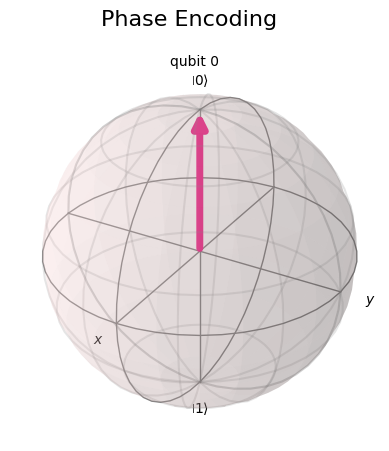

In [14]:
plot_bloch_multivector(state, title='Phase Encoding')


<!-- 5 -->
<div style="background-color:#e6ccff; color:#660099; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">5. Time Evolution (Hamiltonian) Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Uses quantum evolution over time under a Hamiltonian.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Physically motivated and natural for simulations.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Requires time control and known Hamiltonian.</p>


In [15]:
import numpy as np
from scipy.linalg import expm

qc_time = QuantumCircuit(1)
t = 5
# Define Pauli-Z matrix
Z = np.array([[1, 0],
              [0, -1]])
# Calculate time evolution operator
U = expm(-1j * Z * t / 2)
qc_time.unitary(U, 0, label="TimeEvo")

backend = Aer.get_backend('statevector_simulator')
tqc = transpile(qc_time, backend)
result = backend.run(tqc).result()
state = result.get_statevector()

print("Time Evolution Encoding statevector:")
print(state)



Time Evolution Encoding statevector:
Statevector([-0.80114362-0.59847214j, -0.        +0.j        ],
            dims=(2,))


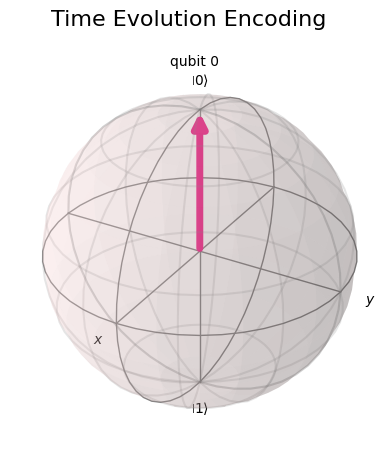

In [16]:
plot_bloch_multivector(state, title='Time Evolution Encoding')

p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Complex to prepare and requires normalization.</p>

<!-- 7 -->
<div style="background-color:#ffd9b3; color:#994d00; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">6. Gray Code Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Minimizes bit flips between successive states.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Reduces error during quantum transitions.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Mapping becomes complex for large datasets.</p>



In [21]:
def binary_to_gray(n: int) -> str:
    b = bin(n)[2:].zfill(3)
    gray = b[0]
    for i in range(1, len(b)):
        gray += str(int(b[i-1] != b[i]))
    return gray

num = 5
gray_str = binary_to_gray(num)
print("Gray code for 5:", gray_str)

qc_gray = QuantumCircuit(len(gray_str))
# Prepare basis state corresponding to Gray code bits.
# Qiskit orders qubits in reverse order relative to bit string.
for idx, bit in enumerate(reversed(gray_str)):
    if bit == '1':
        qc_gray.x(idx)

backend = Aer.get_backend('statevector_simulator')
tqc = transpile(qc_gray, backend)
result = backend.run(tqc).result()
state = result.get_statevector()

print("Gray Code Encoding statevector:")
print(state)



Gray code for 5: 111
Gray Code Encoding statevector:
Statevector([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             1.+0.j],
            dims=(2, 2, 2))


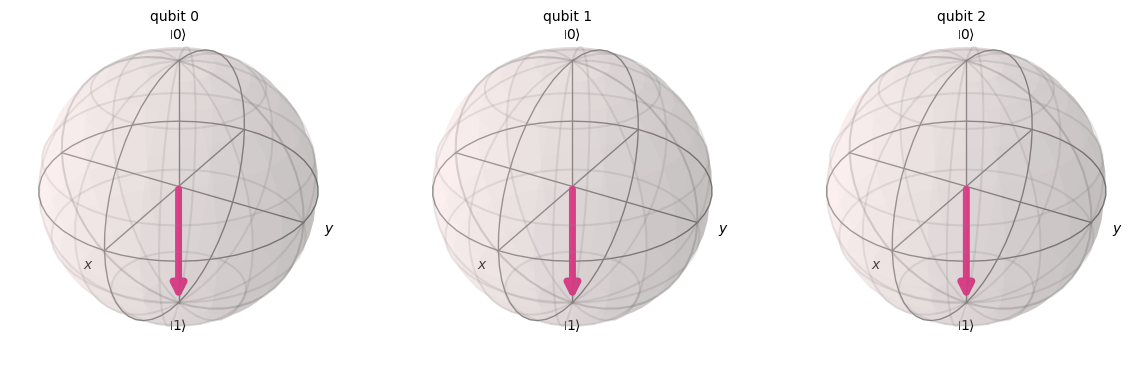

In [22]:
plot_bloch_multivector(state)


<!-- 8 -->
<div style="background-color:#ffccf2; color:#b30059; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">7. Scaled Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Rescales input to fit within quantum gate range.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Easy to implement and interpret.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: May lose precision depending on scale.</p>


In [23]:
import numpy as np

qc_scaled = QuantumCircuit(1)
max_val = 10
theta_scaled = (5 / max_val) * np.pi
qc_scaled.ry(theta_scaled, 0)

backend = Aer.get_backend('statevector_simulator')
tqc = transpile(qc_scaled, backend)
result = backend.run(tqc).result()
state = result.get_statevector()

print("Scaled Encoding statevector:")
print(state)



Scaled Encoding statevector:
Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))


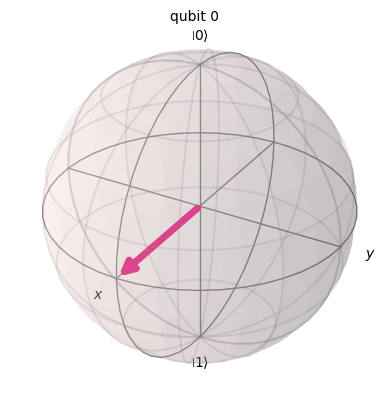

In [24]:
plot_bloch_multivector(state)


<!-- 9 -->
<div style="background-color:#d6f5d6; color:#336633; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">8. Entangler-Enhanced Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Adds entanglement to capture data interactions.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Boosts expressiveness of the encoding circuit.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Increased decoherence and circuit depth.</p>


In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_state_qsphere
import matplotlib.pyplot as plt

# Create the entangled circuit with a rotation encoding on qubit 0.
qc_entangler = QuantumCircuit(2)
qc_entangler.h(0)
qc_entangler.cx(0, 1)
qc_entangler.ry(5, 0)

backend = Aer.get_backend('statevector_simulator')
tqc = transpile(qc_entangler, backend)
result = backend.run(tqc).result()
state = result.get_statevector()

print("Entangler-Enhanced Encoding statevector:")
print(state)


Entangler-Enhanced Encoding statevector:
Statevector([-0.56649408+0.j,  0.42318371+0.j, -0.42318371+0.j,
             -0.56649408+0.j],
            dims=(2, 2))


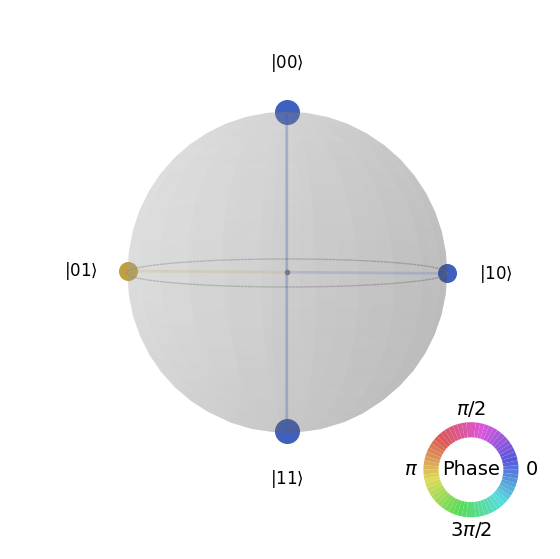

In [2]:
# Visualize the full 2-qubit state with qsphere.
plot_state_qsphere(state)


<!-- 6 -->
<div style="background-color:#ccffff; color:#006666; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">9. Superdense Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Sends 2 classical bits using 1 entangled qubit.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Efficient use of qubit resources in communication.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Needs entanglement and Bell-state measurement.</p>



In [3]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_state_qsphere
import matplotlib.pyplot as plt

qc_superdense = QuantumCircuit(2)
# Create a Bell pair.
qc_superdense.h(0)
qc_superdense.cx(0, 1)
# For classical bits "01" (from 5 mod 4), apply X on qubit 0.
qc_superdense.x(0)

backend = Aer.get_backend('statevector_simulator')
tqc = transpile(qc_superdense, backend)
result = backend.run(tqc).result()
state = result.get_statevector()

print("Superdense Encoding statevector:")
print(state)

Superdense Encoding statevector:
Statevector([0.        +0.j, 0.70710678+0.j, 0.70710678+0.j,
             0.        +0.j],
            dims=(2, 2))


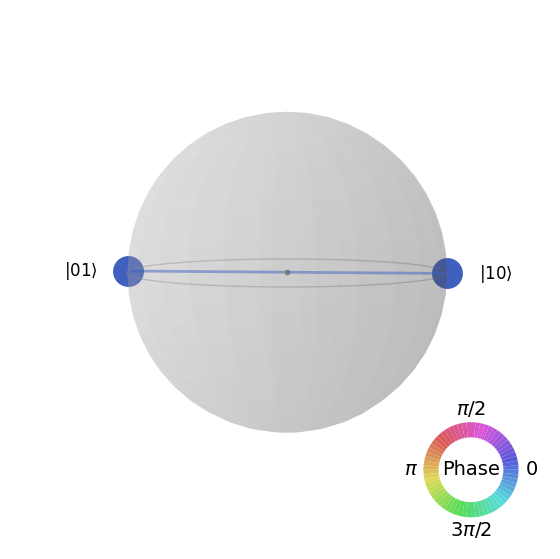

In [4]:
# Visualize the full state with qsphere.
plot_state_qsphere(state)